[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/06-backtesting.ipynb)

# Backtesting: Rolling Origins and Honest Comparison

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Choose between expanding and sliding windows and run a rolling-origin backtest.</li>
<li>Show how shuffled cross-validation inflates a time-series score.</li>
<li>Compare forecasters pairwise over many origins with a standard error.</li>
<li>Use the worst-case days to find what a model cannot see.</li>
</ul>
</div>

**Prerequisites:** Pages 1 to 5 of this track. **Dataset:** NYC Taxi (Jan to Mar 2023). **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

We now have several forecasters and some contradictory impressions. On the baselines page, the best number of weeks to average flipped between two fortnights. On the classical-models page, a regression with AR errors looked 5% better than the four-week average on 14 days, and then turned out to equal a six-week average. How would we ever *know* which forecaster is better?

The answer is **backtesting**: evaluate over many forecast origins, not one, then ask how much of the difference could be luck. This page also settles the question of how *not* to cross-validate a time series.

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from statsmodels.tsa.statespace.sarimax import SARIMAX

y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()
H = 24

## 1. How to split a time series

Ordinary cross-validation shuffles rows into folds. For a series that is wrong twice over: a fold can train on the *future* of its test rows, and its neighbouring hours (almost identical to the test hour) sit in the training data. Time-aware schemes always train on the past and test on what follows, either with a window that **expands** (all history up to the origin) or one that **slides** (only the most recent *w* observations).

scikit-learn offers `TimeSeriesSplit`; our `fc.rolling_origins` + `fc.backtest` does the same with real dates, a forecast horizon and one origin per day. First, the picture of a few origins.

48 daily origins from 2023-02-12 to 2023-03-31


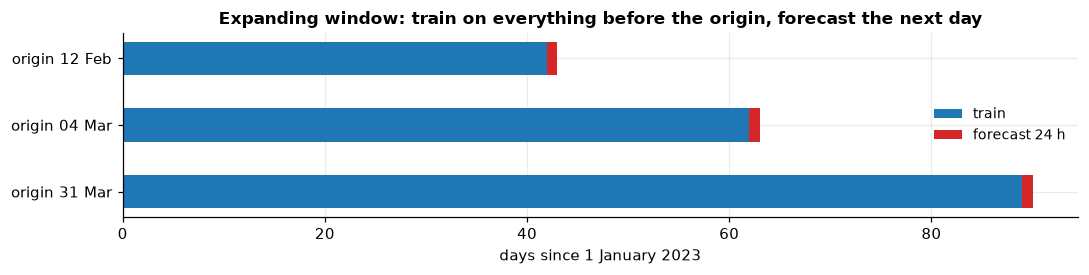

In [3]:
origins = fc.rolling_origins(y.index, first_origin="2023-02-12")
print(len(origins), "daily origins from", origins[0].date(), "to", origins[-1].date())

fig, ax = plt.subplots(figsize=(10, 2.6))
for row, origin in enumerate([origins[0], origins[20], origins[-1]]):
    ax.barh(row, (origin - y.index[0]).total_seconds() / 86400, left=0, height=0.5, color="tab:blue", label="train" if row == 0 else None)
    ax.barh(row, 1, left=(origin - y.index[0]).total_seconds() / 86400, height=0.5, color="tab:red", label="forecast 24 h" if row == 0 else None)
ax.set(yticks=[0, 1, 2], yticklabels=[o.strftime("origin %d %b") for o in (origins[0], origins[20], origins[-1])],
       xlabel="days since 1 January 2023", title="Expanding window: train on everything before the origin, forecast the next day"); ax.legend(loc="center right")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

The first origin trains on six weeks, the last on almost thirteen; each forecast covers the next 24 hours, and then the origin advances one day.

## 2. Why shuffled cross-validation lies

Take the gradient-boosting features from the last page and score them three ways on the same rows: random 5-fold, `TimeSeriesSplit` (five consecutive one-week test blocks, each trained only on what precedes it), and the same with a 24-hour `gap` between train and test.

In [4]:
X = fc.make_features(y, min_lag=24, lags=(24, 48, 168, 336, 504), windows=(24, 168))
X["same_hour_4w"] = pd.concat([y.shift(168 * k) for k in (1, 2, 3, 4)], axis=1).mean(axis=1)
data = X.join(y.rename("target")).dropna()
features, target = data.drop(columns="target"), data["target"]
model = lambda: HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0)

schemes = {
    "random 5-fold (shuffled)": KFold(5, shuffle=True, random_state=0),
    "TimeSeriesSplit: 5 weekly test blocks": TimeSeriesSplit(5, test_size=168),
    "TimeSeriesSplit with a 24-hour gap": TimeSeriesSplit(5, test_size=168, gap=24),
}
cv = {}
for name, splitter in schemes.items():
    mae_folds = -cross_val_score(model(), features, target, cv=splitter, scoring="neg_mean_absolute_error")
    cv[name] = {"mean MAE": mae_folds.mean(), "worst fold": mae_folds.max(), "best fold": mae_folds.min()}
pd.DataFrame(cv).T.round(0).astype(int)

,mean MAE,worst fold,best fold
random 5-fold (shuffled),260,280,239
TimeSeriesSplit: 5 weekly test blocks,312,408,263
TimeSeriesSplit with a 24-hour gap,319,408,265


Shuffled cross-validation reports an error of about **260**, the honest forward-in-time scheme about **310 to 320**, so shuffling flatters the model by roughly 17%. (The two are scored on different rows, since `TimeSeriesSplit` only tests on the later weeks, but the direction and the size of the gap are the point.) The model was never wrong in code: every row's features are legal. The leak is in the *split*: the hour either side of a test row is in the training set, and neighbouring hours are nearly identical, so the model can interpolate rather than forecast.

Notice also the spread across folds: the weekly blocks range from about 260 to about 410, so any one holiday-free week can look like a very different model quality from another. That is the case for **many origins**.

## 3. A proper comparison over 48 origins

Five forecasters from earlier pages, tested on 48 daily origins (12 February to 31 March). The slowest two (the regression with AR errors and boosting) take about a minute in total.

In [5]:
def slot_dummies(index):
    slot = pd.Series(index.dayofweek * 24 + index.hour, index=index).astype("category")
    return pd.get_dummies(slot).astype(float).reindex(columns=range(168), fill_value=0.0)

def slot_ar(hist, idx):                                       # page 4: slot dummies + AR(1) errors, last 6 weeks
    hist = hist.iloc[-168 * 6:]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = SARIMAX(hist, exog=slot_dummies(hist.index), order=(1, 0, 0), trend="c").fit(disp=False, maxiter=200)
    return fit.forecast(len(idx), exog=slot_dummies(idx)).to_numpy()

def boosting(hist, idx):                                      # page 5: gradient boosting, all legal features
    rows = X.loc[X.index.isin(hist.index)].dropna()
    return model().fit(rows, hist.loc[rows.index]).predict(X.loc[idx])

forecasters = {
    "same hour last week": lambda hist, idx: fc.seasonal_naive(hist, idx, 168),
    "4-week average": lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4),
    "6-week average": lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=6),
    "slot dummies + AR(1)": slot_ar,
    "gradient boosting": boosting,
}
train_scale = y[:"2023-02-11"]                                # MASE scale: history before the first origin
runs = {name: fc.backtest(y, f, origins=origins, horizon=H) for name, f in forecasters.items()}
overall = pd.DataFrame({name: fc.score(bt, train_scale) for name, bt in runs.items()}).T
overall.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
same hour last week,338,501,9.4%,0.92
4-week average,281,406,7.7%,0.77
6-week average,281,409,7.6%,0.77
slot dummies + AR(1),280,402,8.4%,0.77
gradient boosting,307,440,9.8%,0.84


Three of the five are in a dead heat (about 280), boosting is clearly behind (about 307) and the weekly copy is last (about 338). Compare this with the single fortnight, where the AR model seemed 5% ahead: on 48 origins its lead is under half a percent.

To see *how* they differ, plot the average error of each forecaster **per origin** (each point is the MAE of one day's 24 forecasts).

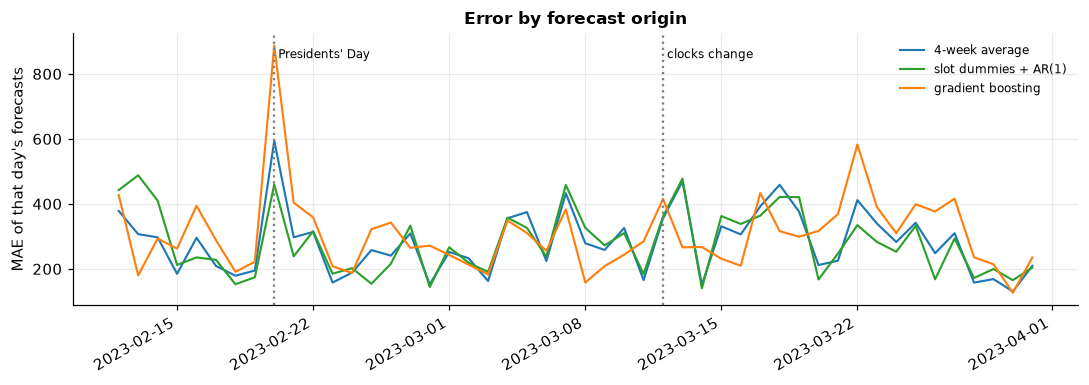

In [6]:
per_origin = pd.DataFrame({name: (bt["actual"] - bt["forecast"]).abs().groupby(bt["origin"]).mean() for name, bt in runs.items()})

fig, ax = plt.subplots(figsize=(10, 3.6))
for name, color in [("4-week average", "tab:blue"), ("slot dummies + AR(1)", "tab:green"), ("gradient boosting", "tab:orange")]:
    ax.plot(per_origin.index, per_origin[name], lw=1.4, color=color, label=name)
for day, label in [("2023-02-20", "Presidents' Day"), ("2023-03-12", "clocks change")]:
    ax.axvline(pd.Timestamp(day), color="grey", ls=":"); ax.text(pd.Timestamp(day), ax.get_ylim()[1] * 0.95, " " + label, fontsize=8, va="top")
ax.set(ylabel="MAE of that day's forecasts", title="Error by forecast origin"); ax.legend(loc="upper right", fontsize=8)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

The three curves move together: **what makes a day hard is the day, not the model**. Days differ in difficulty by a factor of four or more (from about 130 to over 590 for the four-week average). A comparison on a handful of days is therefore dominated by which days happened to be included.

## 4. Are the differences real?

Because every forecaster is scored on the *same* origins, we can compare them **pairwise**, day by day, which removes the shared difficulty. For each pair: the average daily difference, its standard error, and how many of the 48 days the first one wins.

In [7]:
def paired(a, b):
    d = per_origin[a] - per_origin[b]                      # negative = a is better
    return {"mean difference (pickups/hour)": d.mean(), "standard error": d.std() / np.sqrt(len(d)),
            "days a wins": int((d < 0).sum()), "of": len(d)}

pairs = [("slot dummies + AR(1)", "4-week average"), ("6-week average", "4-week average"),
         ("gradient boosting", "4-week average"), ("same hour last week", "4-week average")]
comparison = pd.DataFrame({f"{a}  minus  {b}": paired(a, b) for a, b in pairs}).T
comparison.style.format({"mean difference (pickups/hour)": "{:+.1f}", "standard error": "{:.1f}", "days a wins": "{:.0f}", "of": "{:.0f}"})

,mean difference (pickups/hour),standard error,days a wins,of
slot dummies + AR(1) minus 4-week average,-1.1,7.5,22,48
6-week average minus 4-week average,+0.1,6.7,23,48
gradient boosting minus 4-week average,+26.0,13.3,18,48
same hour last week minus 4-week average,+56.8,17.2,16,48


Read each row against its own standard error:

- **Slot dummies + AR(1) versus the 4-week average: about −1 ± 7.5**, and it wins 22 days of 48. This is a tie, and the regression's apparent 5% edge on the last fortnight was luck.
- **6-week versus 4-week average: 0 ± 7**. Also a tie, and so the "best number of weeks" question from the baselines page has no answer here that the data can support.
- **Boosting versus the 4-week average: about +26 ± 13**. Roughly two standard errors worse, and it wins only 18 days: probably genuinely worse on this series.
- **Seasonal naive versus the 4-week average: about +57 ± 17**, clearly worse on average, but it still wins 16 of the 48 individual days. Averaging four weeks costs something on days that really are like last week.

A difference smaller than about two standard errors should not be reported as a win. Here the honest summary is: *three methods are indistinguishable, boosting is worse, and a plain weekly copy is worst*; **pick the simplest of the tied ones**.

Do the rankings hold when we split the period in half?

In [8]:
first_half = per_origin.index < "2023-03-06"
halves = pd.DataFrame({"12 Feb to 5 Mar": per_origin[first_half].mean(), "6 to 31 Mar": per_origin[~first_half].mean()})
halves.round(0).astype(int).T

,same hour last week,4-week average,6-week average,slot dummies + AR(1),gradient boosting
12 Feb to 5 Mar,347,270,269,271,309
6 to 31 Mar,330,291,291,288,306


The ordering of the top three swaps from one half to the other (differences of one to three pickups). Boosting and the weekly copy stay behind in both halves, but the gaps change size. Rankings among close models are not stable, which is the same message again.

## 5. The hardest days

Which origins hurt the most? A look at the worst days for the four-week average, with the weekly copy alongside.

In [9]:
worst = per_origin[["4-week average", "same hour last week"]].assign(weekday=per_origin.index.day_name()).nlargest(6, "4-week average")
print(worst.round(0).to_string())
print("\nThe origin where the weekly copy fails most:")
bad_copy = per_origin["same hour last week"].idxmax()
per_origin.loc[[bad_copy]].round(0).assign(weekday=bad_copy.day_name())

            4-week average  same hour last week    weekday
origin                                                    
2023-02-20          594.00               700.00     Monday
2023-03-13          469.00               330.00     Monday
2023-03-18          459.00               447.00   Saturday
2023-03-07          433.00               571.00    Tuesday
2023-03-22          412.00               584.00  Wednesday
2023-03-17          392.00               546.00     Friday

The origin where the weekly copy fails most:


,same hour last week,4-week average,6-week average,slot dummies + AR(1),gradient boosting,weekday
origin,,,,,,
2023-02-27,739.00,309.00,356.00,333.00,265.00,Monday


**Monday 20 February (Presidents' Day) is the worst day for the four-week average by a wide margin** (about 590 against a typical 280), and the model had no way to know it was a holiday. And the second table shows where the *weekly copy* fails most: **Monday 27 February**, where its error jumps to about 740 (the four-week average: about 310) because "same hour last week" copied the **holiday**. A forecaster can be wrong on a *normal* day because the reference day was abnormal.

Holidays are information that exists in advance and can be given to a model. That is the subject of the last page of this track.

<div class="admonition tip">
<p class="admonition-title">How to report a backtest</p>
<p>State the origins and the horizon before you look at results. Report the average over all origins <em>and</em> the spread (per-origin or per-fold), the worst cases, and paired differences with standard errors against a baseline. A single number such as "MAE 280" hides most of what a reader needs to decide.</p>
</div>

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| CV score much better than live performance | shuffled folds train on the future and on neighbouring hours | `TimeSeriesSplit` or a rolling-origin backtest |
| Ranking changes when the window changes | few origins, heavy day-to-day difficulty | many origins; paired comparison with standard errors |
| "5% better" disappears on more data | luck on a short window | look at the standard error before celebrating |
| Seasonal-naive forecast is wrong after a holiday | the copied day was abnormal | give the model holiday information, or use a robust average |
| Train and test rows overlap in time | lags or targets span the boundary | use `gap=` at least the feature or target length |
| Tuning on the backtest, then reporting it | selection bias | tune on earlier origins, report on later ones, once |

## Check yourself

<details class="question">
<summary>1. Why does random K-fold cross-validation look better than the honest scheme on the same data, even though no feature leaks?</summary>

The leak is in the **split**, not the features. A test hour's neighbours (one hour before and after) are in the training folds and look almost the same, so the model can effectively interpolate between known points instead of forecasting the unknown. It also trains on data from the test row's future. Real forecasting has neither advantage, so the shuffled score is optimistic (about 17% here).

</details>

<details class="question">
<summary>2. The difference between two models is −3 pickups per hour with a standard error of 7. What do you conclude?</summary>

Nothing: the difference is under half a standard error, so a result of this size appears by chance all the time. The models are indistinguishable on this evidence; choose the simpler or cheaper one. To detect a difference this small you would need many more origins, or a longer history, or to accept that it does not matter.

</details>

<details class="question">
<summary>3. Why compare models pairwise, on the same origins, rather than just comparing their overall averages?</summary>

Because most of the variation between days is shared by all models (some days are simply hard). Subtracting one model's error from another's **cancels the shared difficulty** and leaves only the difference the models make, which has a much smaller standard error than the averages themselves. It is the same logic as a paired t-test.

</details>

## Exercises

<details class="question">
<summary>Compute the standard error and a 95% bootstrap interval for the difference between the slot-dummy model and the 4-week average, by resampling the 48 origins with replacement 5,000 times. Does the interval contain zero?</summary>

```python
rng = np.random.default_rng(0)
d = (per_origin["slot dummies + AR(1)"] - per_origin["4-week average"]).to_numpy()
boot = [rng.choice(d, size=len(d), replace=True).mean() for _ in range(5000)]
print(np.percentile(boot, [2.5, 97.5]))
```

The interval is roughly −16 to +14 pickups per hour, which comfortably contains zero. A bootstrap resamples whole days, which respects that each day's forecasts are a unit; resampling individual hours would give an interval that is far too narrow, because errors within a day are strongly correlated.

</details>

<details class="question">
<summary>Break the error down by forecast step (1 to 24) for the 4-week average and for the slot-dummy model over all 48 origins. In which steps does the AR model win?</summary>

```python
by_step = pd.DataFrame({name: (bt["actual"] - bt["forecast"]).abs().groupby(bt["step"]).mean()
                        for name, bt in runs.items() if name in ("4-week average", "slot dummies + AR(1)")})
print((by_step["4-week average"] - by_step["slot dummies + AR(1)"]).round(0).tolist())
```

The AR model gains in steps 1 and 2 (about 45 and 14 pickups; the memory of the AR(1) term, as on page 4), loses at steps 3 to 5, wins again at steps 8 and 9 (about 40 to 45), and bounces either side of zero for the rest, with no pattern. Over a whole day this nets out to nothing, which is why the overall difference is so small.

</details>

<details class="question">
<summary>Drop the Presidents' Day origin (20 February) and recompute the table. Do the conclusions change?</summary>

```python
print(per_origin.drop(pd.Timestamp("2023-02-20")).mean().round(0))
```

The averages of the top three fall to about 275 to 277 (they were about 280), the boosting gap shrinks a little, and the ordering of the three leaders is still a tie: dropping one hard day moves all the models together, and the conclusions stand. That is a robustness check worth doing, as long as you report that you did it rather than silently dropping days that look bad.

</details>

## Recap

- **Never shuffle a time series** into folds. Use a rolling-origin backtest or `TimeSeriesSplit` (with `gap=` when features or targets span the boundary). Shuffling flattered this model by about 17%.
- Evaluate over **many origins**; day-to-day difficulty varies fourfold.
- Compare models **pairwise** on the same origins and report the **standard error**. A difference under two standard errors is not a win.
- Here three methods tied at about 280 pickups of error; boosting was worse, a weekly copy worst. Choose the simplest of the tied.
- Hard days reveal what the models cannot see (a holiday). Which leads to the final page.

**Next:** *Forecast metrics and prediction intervals*.